# Analyse exploratoire d'EuroSAT (version RGB)

Avant d'entraîner quoi que ce soit, je regarde les données : combien d'images, combien par classe, à quoi elles ressemblent, si certaines sont abîmées ou en double, et ce qui distingue les classes.

**Rappel sur les données.** EuroSAT est construit à partir d'images Sentinel-2 (programme Copernicus). Le satellite mesure 13 bandes spectrales, à 10, 20 ou 60 m de résolution selon la bande. La version utilisée ici ne garde que les bandes rouge, verte et bleue (B4, B3, B2, à 10 m), en JPG 8 bits. On perd donc notamment le proche infrarouge (B8), très utile pour séparer la végétation de l'eau ou du sol nu. Une version à 13 bandes existe (EuroSAT MS), en GeoTIFF.

Le notebook se lance depuis le dossier `notebooks/`, d'où les chemins en `../data/`.

In [2]:
import torch

## 1. Volume et équilibre des classes

Une image par fichier, un dossier par classe. Je compte les fichiers de chaque dossier : si une classe était beaucoup plus rare que les autres, il faudrait pondérer la perte ou rééchantillonner, et surveiller son F1 en particulier.

In [3]:
from pathlib import Path
p = Path("../data/raw/eurosat/2750")
print(list(p.iterdir()))

dir = {d.name: len(list(d.glob("*.jpg"))) for d in p.iterdir() if d.is_dir()}
print(dir)

[WindowsPath('../data/raw/eurosat/2750/AnnualCrop'), WindowsPath('../data/raw/eurosat/2750/Forest'), WindowsPath('../data/raw/eurosat/2750/HerbaceousVegetation'), WindowsPath('../data/raw/eurosat/2750/Highway'), WindowsPath('../data/raw/eurosat/2750/Industrial'), WindowsPath('../data/raw/eurosat/2750/Pasture'), WindowsPath('../data/raw/eurosat/2750/PermanentCrop'), WindowsPath('../data/raw/eurosat/2750/Residential'), WindowsPath('../data/raw/eurosat/2750/River'), WindowsPath('../data/raw/eurosat/2750/SeaLake')]
{'AnnualCrop': 3000, 'Forest': 3000, 'HerbaceousVegetation': 3000, 'Highway': 2500, 'Industrial': 2500, 'Pasture': 2000, 'PermanentCrop': 2500, 'Residential': 3000, 'River': 2500, 'SeaLake': 3000}


<Axes: >

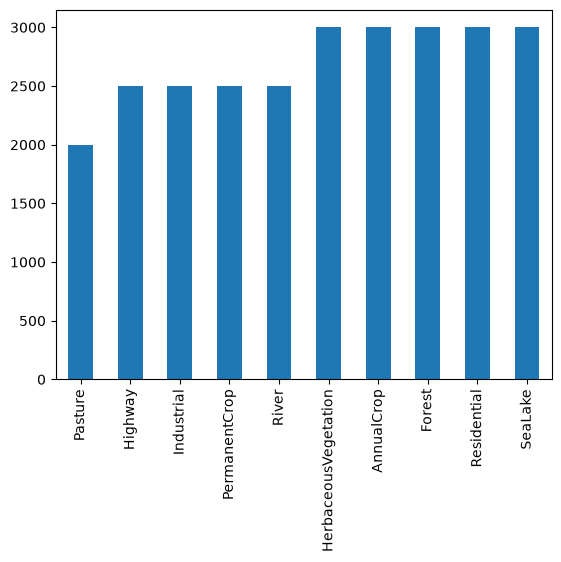

In [4]:
import pandas

df = pandas.Series(dir)
df.sort_values().plot.bar()


De 2 000 (Pasture) à 3 000 images par classe, soit un rapport max/min de 1,5. C'est presque équilibré : pas besoin de pondérer les classes. Je suivrai quand même le F1 macro plutôt que l'accuracy, pour que chaque classe compte autant.

## 2. À quoi ressemblent les images ?

5 images tirées au hasard par classe.

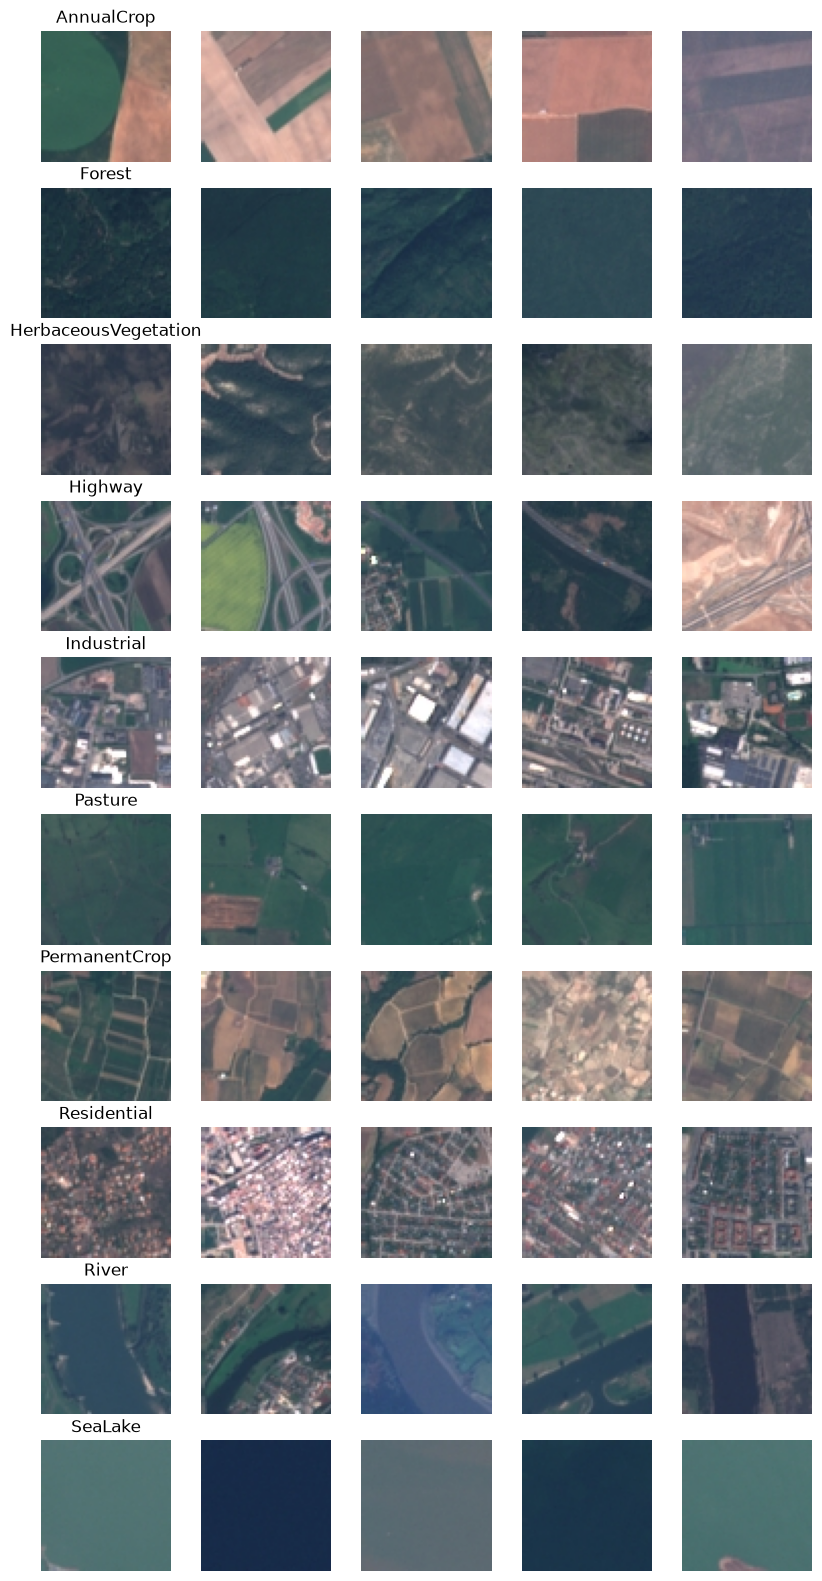

In [7]:
import numpy as np, random, hashlib, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

fichiers_par_classe = {d.name: list(d.glob("*.jpg")) for d in p.iterdir() if d.is_dir()}

fig, axes = plt.subplots(10, 5, figsize=(10, 20))
for i, (classe, fichiers) in enumerate(fichiers_par_classe.items()):
    echantillon = random.sample(fichiers, 5)
    for j, f in enumerate(echantillon):
        axes[i, j].imshow(Image.open(f))
        axes[i, j].axis("off")
    axes[i, 0].set_title(classe)

Ce qu'on voit :
- les couleurs varient beaucoup à l'intérieur d'une même classe (saison, heure de passage, correction atmosphérique) ;
- certaines images sont mixtes : une image Highway peut contenir des champs ou du bâti industriel. Avec une seule étiquette par image, un score de 100 % est hors d'atteinte.

## 3. Format d'une image

Une image fait 64 x 64 pixels. Un pixel Sentinel-2 en RGB couvre 10 m, donc une image couvre environ 640 m de côté.

In [11]:
# Quelle est la forme d'une image : 

a = np.array(Image.open(fichiers_par_classe["Forest"][100]))  # image -> tableau de nombres

print(a.shape, a.dtype, a.min(), a.max())                    # attendu : (64, 64, 3) uint8 0..255


(64, 64, 3) uint8 24 89


## 4. Qualité : tailles, doublons, fichiers illisibles

Une empreinte md5 par fichier permet de repérer les doublons exacts. Un doublon partagé entre le train et le test gonflerait le score sans que le modèle ait rien appris. Cette méthode ne détecte pas les quasi-doublons (même zone, légèrement décalée).

In [12]:
# Controle de la qualité des données 

tailles, hashes, doublons, problemes = set(), {}, [], []

for classe, fichiers in fichiers_par_classe.items():
    for f in fichiers:
        h = hashlib.md5(f.read_bytes()).hexdigest()   # empreinte du fichier : deux fichiers identiques ont la même
        if h in hashes:
            doublons.append((f, hashes[h]))            # même image déjà vue
        else:
            hashes[h] = f
        try:
            im = Image.open(f)
            tailles.add((im.size, im.mode))            # on attend uniquement {((64, 64), 'RGB')}
        except Exception as e:
            problemes.append((f, e))                   # fichier illisible
print(tailles, len(doublons), len(problemes))

{((64, 64), 'RGB')} 0 0


Toutes les images sont en RGB 64 x 64, aucun doublon exact, aucun fichier illisible.

## 5. Couleur moyenne par classe

Si la couleur moyenne suffisait à séparer les classes, un modèle simple suffirait. Je calcule la moyenne R, G, B sur 200 images par classe.

In [16]:
moyennes = {}

for classe, fichiers in fichiers_par_classe.items():
    echantillon = random.sample(fichiers, 200)
    lot = np.stack([np.array(Image.open(f)) for f in echantillon])  # Stacks de (200, 64, 64, 3)
    moyennes[classe] = lot.mean(axis=(0,1,2))
print(pd.DataFrame(moyennes, index=["R","G","B"]).T.round(1))


                          R      G      B
AnnualCrop            132.3  121.1  117.7
Forest                 39.8   64.7   76.5
HerbaceousVegetation   98.4   99.4  103.7
Highway                88.0   96.4  103.3
Industrial            122.8  125.1  133.5
Pasture                63.8   89.3   95.9
PermanentCrop         123.7  116.9  115.3
Residential           101.7  104.8  113.9
River                  65.9   85.9   96.3
SeaLake                47.5   71.8   88.6


Plusieurs paires de classes ont une couleur moyenne presque identique : AnnualCrop et PermanentCrop, Pasture et River, Highway et HerbaceousVegetation. La couleur seule ne suffira pas : le modèle devra exploiter la texture et la forme (rangées d'arbres, tracé d'une route, méandres d'une rivière).

# Conclusion
- EuroSAT fournit 27 000 images RGB de 64 x 64 en 10 classes (de 2 000 à 3 000 images par classe), presque équilibrées.
- Les images sont propres : même format partout, aucun doublon exact, aucun fichier illisible.
- Les couleurs varient beaucoup à l'intérieur d'une classe, et certaines classes se ressemblent beaucoup en couleur.

# Limites
- **Une seule étiquette par image**, alors que le terrain est souvent mixte (il y a des images que j'aurais pu mettre dans deux classes).
- **RGB seul, en 8 bits** : le proche infrarouge n'y est plus, alors qu'il aiderait à séparer végétation, eau et sol. EuroSAT existe aussi en version multispectrale (13 bandes).
- **Une seule date par image** : impossible d'utiliser l'évolution d'une parcelle au fil de la saison, qui est souvent ce qui distingue deux cultures.
- **Pas de coordonnées** dans cette version. Deux images voisines peuvent donc se retrouver l'une dans le train, l'autre dans le test, sans qu'on le sache. C'est un risque de fuite (autocorrélation spatiale), et les scores obtenus seront probablement un peu optimistes. Un découpage spatial (par zone géographique) n'est pas possible ici.
- **Données européennes** (34 pays) : un modèle entraîné ici ne se transposerait pas tel quel à d'autres régions, d'autres cultures ou d'autres paysages.

## Conséquences pour la suite
- Découpage train / validation / test stratifié, fait une seule fois avant toute transformation (`src/make_splits.py`).
- Métrique principale : F1 macro, complété par le F1 par classe et la matrice de confusion.
- Augmentations géométriques seulement (miroirs, rotations de 90°) : une vue de dessus n'a ni haut ni bas, et la couleur porte de l'information, donc on ne la modifie pas.